# Licetum check API: load test results

This notebook draws the results of the load test of the check API made with `licetum-loadtest`. It reads only the
`result.json` and `environment.json` files of the runs, not the raw requests. Set `LICETUM_RESULTS` to the directory
that holds your runs (the default is `results/`, the runs published next to this notebook). [README.md](README.md)
says how the runs are made and how to get the same charts on your own machine.

How to read it:

- A **window** is one measured period at a fixed arrival rate, or one step of a ramp.
- Only **valid** windows enter the medians. A window is invalid when requests were dropped, when the load generator
  used more than 70 % of its CPUs, or when the oracle found a wrong answer. Invalid windows stay in the tables, with
  the reason.
- A percentile is shown only from enough samples: 100/(1 - q), so a p99 needs 10,000 requests.
- The runs of one configuration should give the same numbers. When they do not, the machine was in different states
  during the runs. The charts show every run, not only the median, for that reason.

## Status of these results

These are the first published runs, and they are preliminary. Each configuration name ends with the commit and the CPU
governor of its runs.

- `clean-0ff9a6b7`: a clean tree, the `performance` governor, no swap. The 10k profile, warm mode, 200 requests/s. Two
  valid windows; run 3 is invalid because the host swapped memory during it; run 4 is invalid because it was stopped by
  hand. These are the only windows that would count for a clean configuration.
- `dirty-3cd0b4c3`: the first attempt, with uncommitted changes, the `powersave` governor and swap in use. Five valid
  windows, kept to show how far the state of the host moves the same code: the p99 of the permission check is about
  23 ms in some runs and about 120 ms in others. It is not a result of the code.
- Not measured yet: the 100k profile, the mixed, cold and ramp modes, writes during load, faults, and a second machine.
  Nothing here is a number for an article on its own.

## Load the results

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%config InlineBackend.figure_format = "svg"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

ORDER = ["permission", "check1", "check10", "check100", "authzen", "authzen_batch", "on_behalf"]
ENV_COLUMNS = ["cpu_model", "logical_cpus", "kernel", "cpu_governor", "k6_version", "postgres_version",
               "git_commit", "git_dirty", "k6_cpus", "check_cpus"]
QUANTILES = {"p50": 0.5, "p90": 0.9, "p95": 0.95, "p99": 0.99, "p999": 0.999}
SPREAD_LIMIT = 0.15  # above this spread of the p99 a configuration is unstable; the report uses the same limit

ROOT = Path(os.environ.get("LICETUM_RESULTS", "results"))
if not ROOT.is_dir():
    raise FileNotFoundError(f"no results directory at {ROOT}: set LICETUM_RESULTS to the output of licetum-loadtest")


def published(value, samples, quantile):
    # A quantile is published from 100/(1-q) samples, as the harness does (MinSamples in measure.go).
    if samples is None or samples < np.ceil(100 / (1 - quantile) - 1e-9):
        return np.nan
    return value


def latency_row(lat):
    samples = lat.get("samples", 0)
    row = {name: published(lat.get(name, np.nan), samples, q) for name, q in QUANTILES.items()}
    return {**row, "samples": samples}


windows, operations, storage, effects, environments = [], [], [], [], []
for path in sorted(ROOT.rglob("result.json")):
    doc = json.loads(path.read_text())
    run = path.parent.relative_to(ROOT).as_posix()
    env_path = path.parent / "environment.json"
    env = json.loads(env_path.read_text()) if env_path.exists() else {}
    environments.append({"run": run, **{key: env.get(key) for key in ENV_COLUMNS}})
    settings = (doc.get("settings") or {})
    profile = (doc.get("profile") or {}).get("name", "?")
    ramp = bool(settings.get("ramp"))
    for step, m in enumerate((doc.get("measurements") or [])):
        setup = f"{(env.get('git_commit') or '?')[:7]}{' dirty' if env.get('git_dirty') else ''}, {env.get('cpu_governor', '?')}"
        config = f"{profile} {m['mode']} ramp" if ramp else f"{profile} {m['mode']} {m['rate_asked']:g} rps"
        config = f"{config}, {setup}"
        tags = {"run": run, "config": config, "profile": profile, "mode": m["mode"], "seed": m["seed"],
                "step": step, "ramp": ramp}
        srv = (m.get("server") or {})
        orc = (m.get("oracle") or {})
        overall = latency_row((m.get("latency_all_ms") or {}))
        windows.append({
            **tags,
            "rate_asked": m["rate_asked"], "achieved_rps": m["achieved_rps"], "requests": m["requests"],
            "error_rate": m["error_rate"], "dropped": m["dropped_iterations"], "valid": m["valid"],
            "invalid_reasons": "; ".join((m.get("invalid_reasons") or [])),
            "passed": m.get("passed") if ramp else None,
            "fail_reasons": "; ".join((m.get("fail_reasons") or [])),
            "slo_p99_ms": settings.get("slo_p99_ms"),
            "oracle_checked": orc.get("checked", 0), "oracle_mismatches": orc.get("mismatches", 0),
            "server_cpu_cores": srv.get("cpu_cores"), "k6_cpu_share": m.get("k6_cpu_share"),
            "permission_cache_hit": srv.get("permission_cache_hit_ratio"),
            "check_cache_hit": srv.get("check_cache_hit_ratio"),
            "db_statement_ms_per_request": srv.get("db_statement_ms_per_request"),
            "db_commits_per_request": srv.get("db_commits_per_request"),
            "all_p50": overall["p50"], "all_p90": overall["p90"], "all_p99": overall["p99"],
            "all_p999": overall["p999"], "all_samples": overall["samples"],
        })
        for op in (m.get("operations") or []):
            if op["requests"] == 0:
                continue
            operations.append({**tags, "operation": op["name"], "requests": op["requests"],
                               **latency_row(op["latency_ms"])})
        if m.get("write_effect"):
            effects.append({**tags, "kind": "writes", **m["write_effect"]})
        if m.get("fault_effect"):
            effects.append({**tags, "kind": "fault", **m["fault_effect"]})
    storage.extend({"run": run, "profile": profile, **table} for table in (doc.get("storage") or []))

windows = pd.DataFrame(windows)
if windows.empty:
    raise ValueError(f"no result.json under {ROOT}")
operations = pd.DataFrame(operations)
storage = pd.DataFrame(storage)
environments = pd.DataFrame(environments)
effects = pd.DataFrame(effects)
print(f"{windows.run.nunique()} runs, {len(windows)} windows, {windows.config.nunique()} configurations")

9 runs, 9 windows, 2 configurations


## Environment

Every run writes the environment it ran in next to its results. The table has one row per distinct environment.
Only a run from a clean tree, with the CPU frequency governor set to `performance`, is a fair basis for a published
number. The warnings below name the runs that are not.

In [2]:
distinct = environments.drop(columns="run").drop_duplicates().reset_index(drop=True)
display(distinct)
dirty = environments.loc[environments.git_dirty != False, "run"].tolist()
if dirty:
    print(f"Measured from a tree with uncommitted changes: {len(dirty)} run(s): {', '.join(dirty)}")
slow = environments.loc[environments.cpu_governor != "performance", "run"].tolist()
if slow:
    print(f"The CPU frequency governor is not 'performance' in {len(slow)} run(s); the clock can change during a run.")

,cpu_model,logical_cpus,kernel,cpu_governor,k6_version,postgres_version,git_commit,git_dirty,k6_cpus,check_cpus
0,12th Gen Intel(R) Core(TM) i5-12450H,12,7.2.8-1-cachyos,performance,"k6 v2.2.0 (commit/00a9a1b7f5, go1.26.5, linux/...","PostgreSQL 16.15 on x86_64-pc-linux-musl, comp...",0ff9a6b7ff37a237ca7c84268066ce46d47c04c7,False,10-11,0-7
1,12th Gen Intel(R) Core(TM) i5-12450H,12,7.2.8-1-cachyos,powersave,"k6 v2.2.0 (commit/00a9a1b7f5, go1.26.5, linux/...","PostgreSQL 16.15 on x86_64-pc-linux-musl, comp...",3cd0b4c393be47aada6eedd5fa6b458dace546ba,True,10-11,0-7


Measured from a tree with uncommitted changes: 5 run(s): dirty-3cd0b4c3/smoke-warm/run-1, dirty-3cd0b4c3/smoke-warm/run-2, dirty-3cd0b4c3/smoke-warm/run-3, dirty-3cd0b4c3/smoke-warm/run-4, dirty-3cd0b4c3/smoke-warm/run-5
The CPU frequency governor is not 'performance' in 5 run(s); the clock can change during a run.


## Results at a fixed rate

The medians are over the valid windows of each configuration. The spread below is (max - min) / median of the p99
over those windows: when it is above 15 %, the runs of the configuration were not in the same state.

In [3]:
fixed = windows[~windows.ramp]
valid_fixed = fixed[fixed.valid]
fixed_ops = operations[~operations.ramp & operations.run.isin(valid_fixed.run)]
configs = sorted(fixed_ops.config.unique())

p50 = fixed_ops.pivot_table(index="config", columns="operation", values="p50", aggfunc="median")
p99 = fixed_ops.pivot_table(index="config", columns="operation", values="p99", aggfunc="median")
headline = pd.DataFrame({
    "valid runs": valid_fixed.groupby("config").run.count(),
    "achieved rps": valid_fixed.groupby("config").achieved_rps.median(),
    "error rate (max)": valid_fixed.groupby("config").error_rate.max(),
    "server CPU, cores": valid_fixed.groupby("config").server_cpu_cores.median(),
})
headline = headline.join(p50.reindex(columns=["permission", "check1", "authzen", "on_behalf"]).add_prefix("p50 "))
headline = headline.join(p99.reindex(columns=["permission", "check1", "authzen", "on_behalf"]).add_prefix("p99 "))
display(headline.round(2))

,valid runs,achieved rps,error rate (max),"server CPU, cores",p50 permission,p50 check1,p50 authzen,p50 on_behalf,p99 permission,p99 check1,p99 authzen,p99 on_behalf
config,,,,,,,,,,,,
"smoke warm 200 rps, 0ff9a6b, performance",2,200.0,0,0.29,2.35,1.78,1.78,4.00,13.61,10.31,10.18,14.22
"smoke warm 200 rps, 3cd0b4c dirty, powersave",5,200.0,0,0.42,3.80,3.02,3.04,5.76,23.71,16.56,17.01,24.92


### Run-to-run spread

In [4]:
def spread(values):
    values = values.dropna()
    if len(values) < 2:
        return np.nan
    return (values.max() - values.min()) / values.median()


spreads = fixed_ops.groupby(["config", "operation"]).p99.apply(spread).unstack()
spreads = spreads.reindex(columns=[o for o in ORDER if o in spreads.columns])
display(spreads.round(3))
measured = spreads.notna().sum().sum()
unstable = int((spreads > SPREAD_LIMIT).sum().sum())
print(f"{unstable} of {measured} configuration-operation pairs spread more than {SPREAD_LIMIT:.0%} over their runs")

operation,permission,check1,check10,authzen,authzen_batch,on_behalf
config,,,,,,
"smoke warm 200 rps, 0ff9a6b, performance",0.020,0.024,0.039,0.034,0.044,0.031
"smoke warm 200 rps, 3cd0b4c dirty, powersave",4.358,5.607,6.508,5.573,6.483,4.760


6 of 12 configuration-operation pairs spread more than 15% over their runs


### Every run, with its p99 per operation

Each dot is one valid run; the black tick is the median of its configuration. Runs of the same configuration that sit
apart from each other were in different states.

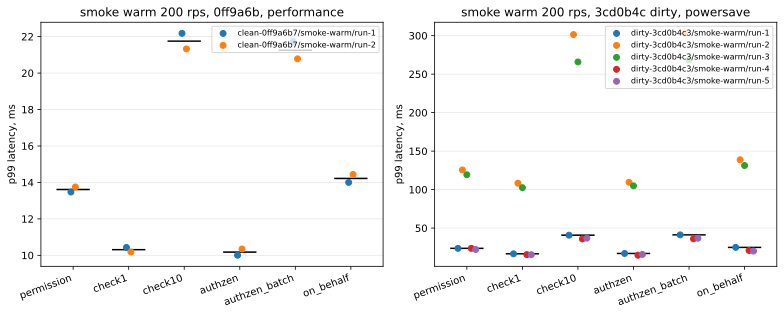

In [5]:
def dot_plot(ax, data, value, title):
    names = [o for o in ORDER if o in set(data.operation)]
    runs = sorted(data.run.unique())
    for ri, run in enumerate(runs):
        rows = data[data.run == run]
        xs = [names.index(o) + (ri - (len(runs) - 1) / 2) * 0.08 for o in rows.operation]
        ax.scatter(xs, rows[value], color=plt.cm.tab10(ri % 10), label=run, zorder=3)
    for xi, name in enumerate(names):
        ax.hlines(data.loc[data.operation == name, value].median(), xi - 0.3, xi + 0.3, color="black", lw=1.5,
                  zorder=2)
    ax.set_xticks(range(len(names)), names, rotation=20, ha="right")
    ax.set_ylabel(f"{value} latency, ms")
    ax.set_title(title)
    ax.legend(fontsize=8, loc="upper right")
    ax.grid(axis="y", alpha=0.3)


if configs:
    fig, axes = plt.subplots(1, len(configs), figsize=(5.5 * len(configs), 4.5), squeeze=False)
    for ax, config in zip(axes[0], configs):
        dot_plot(ax, fixed_ops[fixed_ops.config == config], "p99", config)
    fig.tight_layout()
else:
    print("No valid window at a fixed rate in these results.")

### The windows, valid and invalid

In [6]:
per_run = fixed.set_index("run")[["config", "seed", "rate_asked", "achieved_rps", "error_rate", "dropped",
                                  "oracle_mismatches", "valid", "invalid_reasons"]]
p99_wide = fixed_ops.pivot_table(index="run", columns="operation", values="p99")
per_run = per_run.join(p99_wide.reindex(columns=["permission", "check1", "authzen"]).add_prefix("p99 "))
display(per_run.round(3))

,config,seed,rate_asked,achieved_rps,error_rate,dropped,oracle_mismatches,valid,invalid_reasons,p99 permission,p99 check1,p99 authzen
run,,,,,,,,,,,,
clean-0ff9a6b7/smoke-warm/run-1,"smoke warm 200 rps, 0ff9a6b, performance",1,200,200.002,0,0,0,True,,13.473,10.433,10.005
clean-0ff9a6b7/smoke-warm/run-2,"smoke warm 200 rps, 0ff9a6b, performance",2,200,200.002,0,0,0,True,,13.751,10.186,10.349
clean-0ff9a6b7/smoke-warm/run-3,"smoke warm 200 rps, 0ff9a6b, performance",3,200,200.002,0,0,0,False,the host swapped 410716 pages during the windo...,NaN,NaN,NaN
clean-0ff9a6b7/smoke-warm/run-4,"smoke warm 200 rps, 0ff9a6b, performance",4,200,0.000,0,0,0,False,the window did not finish: k6 measure-01: sign...,NaN,NaN,NaN
dirty-3cd0b4c3/smoke-warm/run-1,"smoke warm 200 rps, 3cd0b4c dirty, powersave",1,200,200.000,0,0,0,True,,23.640,16.561,17.011
dirty-3cd0b4c3/smoke-warm/run-2,"smoke warm 200 rps, 3cd0b4c dirty, powersave",2,200,200.002,0,0,0,True,,125.520,108.298,109.515
dirty-3cd0b4c3/smoke-warm/run-3,"smoke warm 200 rps, 3cd0b4c dirty, powersave",3,200,200.002,0,0,0,True,,119.268,102.511,104.883
dirty-3cd0b4c3/smoke-warm/run-4,"smoke warm 200 rps, 3cd0b4c dirty, powersave",4,200,200.002,0,0,0,True,,23.707,15.552,14.720
dirty-3cd0b4c3/smoke-warm/run-5,"smoke warm 200 rps, 3cd0b4c dirty, powersave",5,200,200.002,0,0,0,True,,22.202,15.434,15.789


## Latency of all requests

The percentiles of every request of a window, the median over the valid runs of a configuration, with the lowest and
the highest run as the error bars. Each point is published only from enough samples.

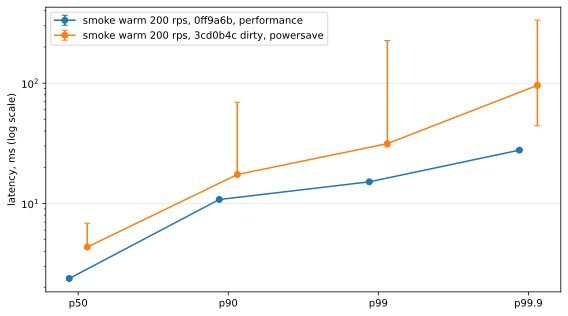

In [7]:
levels = ["all_p50", "all_p90", "all_p99", "all_p999"]
fig, ax = plt.subplots(figsize=(8, 4.5))
for ci, config in enumerate(configs):
    g = valid_fixed[valid_fixed.config == config]
    med = np.array([g[c].median() for c in levels])
    lo = np.array([g[c].min() for c in levels])
    hi = np.array([g[c].max() for c in levels])
    x = np.arange(len(levels)) + (ci - (len(configs) - 1) / 2) * 0.12
    ax.errorbar(x, med, yerr=[med - lo, hi - med], marker="o", capsize=3, label=config)
ax.set_xticks(range(len(levels)), ["p50", "p90", "p99", "p99.9"])
ax.set_yscale("log")
ax.set_ylabel("latency, ms (log scale)")
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()

## Server cost

What the check server spent per valid run: its CPU (cores of the 8 pinned to it), the share of permission answers from
the cache, and the PostgreSQL statement time per request. The check1, check10 and check100 operations share one
server histogram, so the server does not report their latency separately.

In these runs the check server's CPU and its cache hit ratio are nearly the same in every run. The PostgreSQL time per
request is not always the same: the harness does not pin PostgreSQL or Redis to CPUs, so their share of the machine
follows the other load on it. A run with a higher statement time than its siblings is the first place to look when its
latency is higher.

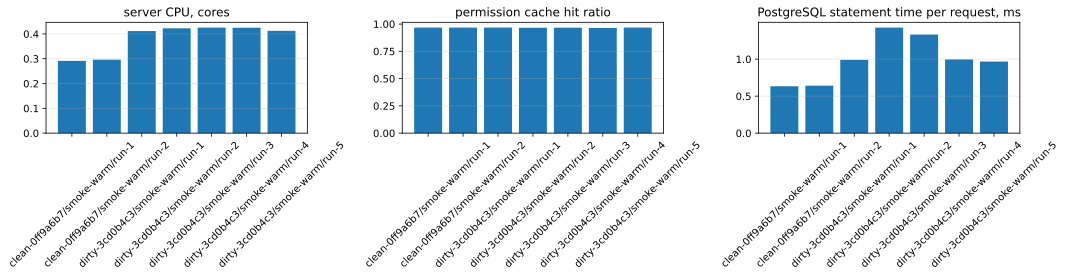

In [8]:
cost = [("server_cpu_cores", "server CPU, cores"),
        ("permission_cache_hit", "permission cache hit ratio"),
        ("db_statement_ms_per_request", "PostgreSQL statement time per request, ms")]
fig, axes = plt.subplots(1, len(cost), figsize=(5 * len(cost), 4))
for ax, (column, label) in zip(axes, cost):
    ax.bar(valid_fixed.run, valid_fixed[column])
    ax.set_title(label)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)
fig.tight_layout()

## Ramp to the knee

A ramp raises the arrival rate step by step. The left chart shows where the achieved rate stops following the asked one;
the right one shows the p99 of each step against the objective (`-slo-p99`). Green steps passed, red ones did not.

In [9]:
ramp = windows[windows.ramp].sort_values(["run", "step"])
if ramp.empty:
    print("No ramp in these results.")
else:
    fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.5))
    left.plot(ramp.rate_asked, ramp.achieved_rps, "o-", label="achieved")
    left.plot(ramp.rate_asked, ramp.rate_asked, "--", color="grey", label="asked")
    left.set_xlabel("asked, requests/s")
    left.set_ylabel("achieved, requests/s")
    left.legend()
    colours = np.where(ramp.passed.fillna(False).astype(bool), "tab:green", "tab:red")
    right.plot(ramp.rate_asked, ramp.all_p99, "-", color="grey")
    right.scatter(ramp.rate_asked, ramp.all_p99, c=colours, zorder=3)
    slo = ramp.slo_p99_ms.dropna()
    if len(slo):
        right.axhline(slo.iloc[0], ls=":", color="black", label="objective")
        right.legend()
    right.set_xlabel("asked, requests/s")
    right.set_ylabel("p99 of all requests, ms")
    fig.tight_layout()
    display(ramp[["run", "step", "rate_asked", "achieved_rps", "error_rate", "all_p99", "valid", "passed",
                  "fail_reasons"]].round(3))

No ramp in these results.


## Writes and faults during load

Writes (a rule created and deleted during the window, so every write drops the caches) and faults (Redis paused) and
what they did to the latency around them. Empty when the results have neither.

In [10]:
if effects.empty:
    print("No writes or faults in these results.")
else:
    display(effects.round(3))

No writes or faults in these results.


## Storage

The size of the tables that hold the policy and the synchronized resources, after the run: the total bytes with their
indexes. The resource tables grow with the resources, so their size per row is the number to scale from.

,profile,table,rows,MiB,index share,bytes per row
0,smoke,resource_cache,10000,3.13,0.61,328.50
1,smoke,resource_edge,9500,1.61,0.50,177.64
2,smoke,resource_ancestor,19500,4.07,0.53,218.87
3,smoke,assignment_rule,1000,0.31,0.42,327.68
4,smoke,group_member,10,0.06,0.75,6553.60
5,smoke,user_group,10,0.05,0.67,4915.20
6,smoke,type_resource,2,0.06,0.75,32768.00


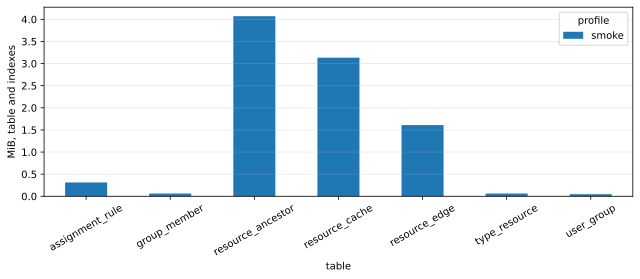

In [11]:
storage_view = storage.drop_duplicates(["profile", "table"]).copy()
storage_view["MiB"] = storage_view["total_bytes"] / 2**20
storage_view["index share"] = storage_view["index_bytes"] / storage_view["total_bytes"]
storage_view["bytes per row"] = storage_view["total_bytes"] / storage_view["rows"].where(storage_view["rows"] > 0)
display(storage_view[["profile", "table", "rows", "MiB", "index share", "bytes per row"]].round(2))
fig, ax = plt.subplots(figsize=(9, 4))
storage_view.pivot_table(index="table", columns="profile", values="MiB").plot.bar(ax=ax)
ax.set_ylabel("MiB, table and indexes")
ax.tick_params(axis="x", rotation=30)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()

## What these numbers are not

- One machine, one database, one check server process (or the replicas named in the settings), with the load
  generator on the cores pinned to it. The numbers say what this setup does, not what a deployment will do.
- Warm-up is 60 seconds, the measured window is 10 minutes for the fixed-rate runs. The first synchronization of a
  service is not in the windows; the cold mode measures every request computed, not a first request after a restart.
- The traffic is generated from a seed. The policy is generated, not a customer's: its shape (owner rules, group and
  department grants, denials with exceptions) is the shape the harness builds, and the answers are checked against
  an independent oracle of that shape only.
- The windows are the valid ones; invalid windows are listed above with their reasons, and nothing is averaged in.

To reproduce these charts with your own runs, follow [README.md](README.md).